In [56]:
import os
import zipfile

zip_path = "/content/machine-deep-learning.zip"
data_path = "/content/project_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(data_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(data_path):
    for name in files:
        print(os.path.relpath(os.path.join(root, name), data_path))

Dataset extracted successfully!
train_queries.csv
test_queries.csv
sample_submission.csv
README.md
knowledge_base/attendance_policy.json
knowledge_base/courses.json
knowledge_base/faculty.json
knowledge_base/academic_calendar.json
knowledge_base/placement_policy.json
knowledge_base/faq.json
knowledge_base/exam_schedule.json
knowledge_base/campus_services.json
knowledge_base/hostel.json
knowledge_base/holidays.json


In [57]:
import os
import pandas as pd
import json
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

base = "/content/project_data"

train_df = pd.read_csv(base + "/train_queries.csv")
test_df = pd.read_csv(base + "/test_queries.csv")

documents = []

kb = base + "/knowledge_base"

for filename in os.listdir(kb):
    if filename.endswith(".json"):
        with open(os.path.join(kb, filename),
                  "r", encoding="utf-8") as f:
            records = json.load(f)

        for item in records:
            text = " ".join(
                str(v) for k, v in item.items()
                if k != "document_id"
            )
            documents.append({
                "document_id": str(item["document_id"]),
                "text": text
            })

docs_df = pd.DataFrame(documents)
docs_df = docs_df.drop_duplicates("document_id")

print("Training samples:", len(train_df))
print("Test samples:", len(test_df))
print("Knowledge-base documents:", len(docs_df))
print("Data loaded successfully!")

Training samples: 110
Test samples: 50
Knowledge-base documents: 190
Data loaded successfully!


Validation Accuracy: 67.86 %


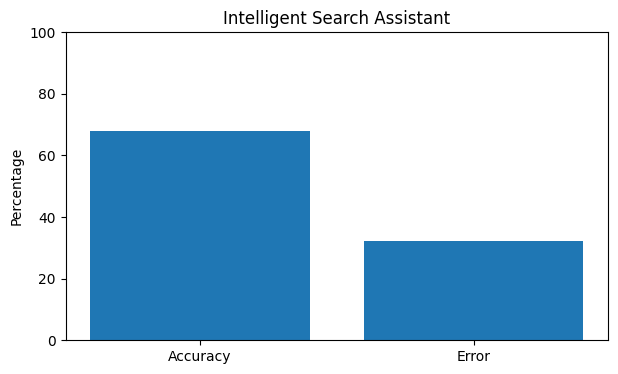

In [58]:
X_train, X_val, y_train, y_val = train_test_split(
    train_df["query"].astype(str),
    train_df["document_id"].astype(str),
    test_size=0.25,
    random_state=42
)

vectorizer = TfidfVectorizer(ngram_range=(1, 2))

train_vectors = vectorizer.fit_transform(X_train)
val_vectors = vectorizer.transform(X_val)

scores = cosine_similarity(val_vectors, train_vectors)

predictions = y_train.iloc[scores.argmax(axis=1)].to_numpy()

accuracy = np.mean(predictions == y_val.to_numpy())

print("Validation Accuracy:", round(accuracy * 100, 2), "%")

plt.figure(figsize=(7, 4))
plt.bar(
    ["Accuracy", "Error"],
    [accuracy * 100, (1 - accuracy) * 100]
)
plt.ylabel("Percentage")
plt.title("Intelligent Search Assistant")
plt.ylim(0, 100)
plt.savefig("/content/accuracy_graph.png", dpi=150)
plt.show()

In [59]:
# Build the final search model
all_queries = train_df["query"].astype(str).tolist()
all_labels = train_df["document_id"].astype(str).tolist()

final_vectorizer = TfidfVectorizer(ngram_range=(1, 2))
all_vectors = final_vectorizer.fit_transform(all_queries)

doc_lookup = dict(
    zip(docs_df["document_id"].astype(str), docs_df["text"])
)

def search_assistant(question):
    q_vector = final_vectorizer.transform([question])
    scores = cosine_similarity(q_vector, all_vectors)[0]

    # Show the three closest training queries
    top_indices = np.argsort(scores)[::-1][:3]

    for rank, idx in enumerate(top_indices, start=1):
        doc_id = all_labels[idx]
        print(f"\nMatch {rank}:")
        print("Similarity:", round(float(scores[idx]), 3))
        print("Document ID:", doc_id)
        print("Information:", doc_lookup.get(
            doc_id, "Document text not found."
        ))

search_assistant("What are the hostel rules?")


Match 1:
Similarity: 0.458
Document ID: HS001
Information: Gate closes at 10 PM

Match 2:
Similarity: 0.393
Document ID: HS001
Information: Gate closes at 10 PM

Match 3:
Similarity: 0.393
Document ID: HS001
Information: Gate closes at 10 PM


In [60]:
from google.colab import files
files.download("/content/accuracy_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
all_queries = train_df["query"].astype(str).tolist()
all_labels = train_df["document_id"].astype(str).tolist()

final_vectorizer = TfidfVectorizer(ngram_range=(1,2))
all_vectors = final_vectorizer.fit_transform(all_queries)

test_vectors = final_vectorizer.transform(test_df["query"].astype(str))
scores = cosine_similarity(test_vectors, all_vectors)
best = scores.argmax(axis=1)

submission = pd.DataFrame({
    "query_id": test_df["query_id"],
    "document_id": [all_labels[i] for i in best]
})

submission.to_csv("/content/submission.csv", index=False)

from google.colab import files
files.download("/content/submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>